# Dissertação de Mestrado: Análise Alométrica Bacia–Mancha Urbana–Microplásticos Costeiros
## Recorte Regional: Estados Unidos ao Canal do Panamá

**Pesquisador:** Thiago  
**Orientador:** Prof. Dr. Erneson A. Oliveira  
**Bases de Dados:** GPW v4 (População CIESIN 2020), GEBCO 2026 (Batimetria e Topografia Global) e NOAA NCEI (Microplásticos Marinhos)

---

### Resumo Metodológico e Fundamentação Teórica
Este notebook implementa a metodologia experimental orientada pelo **Prof. Dr. Erneson Oliveira** para investigar a correlação alométrica entre a população urbana contida em uma bacia hidrográfica e o aporte de microplásticos na foz (sink):

1. **Topografia e Bacias Hidrográficas (IPBA):**
   - Altura de corte $h^* = 0$ (nível do mar): áreas emersas com $h > 0$ formam a massa continental; oceano ($h \le 0$) é tratado como exterior (*Oliveira et al., 2019*).
   - **Sinks costeiros:** Todos os pixels de terra vizinhos imediatos (4-conectividade) de água (linha de costa continental).
   - **Rodada única do IPBA:** Execução direta do *Invasion Percolation-Based Algorithm* até a desembocadura de menor resistência topográfica.
   - **Filtro de área acumulada (95%):** Retém apenas as grandes bacias responsáveis por 95% da área continental.
   - **Exclusão de bacias endorreicas:** Consideram-se exclusivamente bacias que deságuam no oceano.

2. **Manchas Urbanas (GPW v4 + CCA):**
   - *City Clustering Algorithm* (CCA) (*Oliveira et al., 2014, 2018; Operti et al., 2017*).
   - **Calibração dinâmica $D^* \times \ell$:** Varredura em grade adaptativa com densidade $D^*$ até $5.000$ hab/km² e passos de $\ell$, cobrindo pontos como $D^*=1010$ hab/km² e $\ell=1{,}7$ km.
   - Ajuste da **Lei de Zipf** ($\log_{10} P \sim -\alpha \log_{10} r$), selecionando o par ótimo com $\alpha \approx 1$.

3. **Particionamento das Manchas:**
   - Divisão pixel a pixel da população das manchas urbanas transfronteiriças ao longo das linhas de cumeada das bacias, conservando rigorosamente a população total.

4. **Microplásticos NOAA e Pareamento Espacial:**
   - **Raio individualizado por sink:** Cada sink possui seu próprio raio de expansão $r_i^* \le R_{\max}(s_i)$, onde $R_{\max}(s_i) = \min(50, 0{,}5 \cdot d_{\min}(\mathrm{sink\_outro}))$, garantindo zero sobreposição e contagem estritamente exclusiva.

5. **Diagnóstico de Causa-Raiz e Limpeza de Dados:**
   - Comparação sistemática entre resíduos industriais virgens (Nurdles) e microplásticos urbanos pós-consumo (redes de superfície e praias), avaliando o ganho de correlação com a remoção de distorções metodológicas.


In [1]:
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

# Configurar caminhos do projeto
NOTEBOOK_DIR = Path.cwd()
REPO_ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == 'notebooks' else NOTEBOOK_DIR
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from pipeline.ipba_runner import crop_gebco, extract_coastal_sinks, run_ipba, filter_basins_by_area
from pipeline.cca_calibrator import crop_gpw, calibrate_zipf_grid, run_calibrated_cca, plot_zipf_calibration as plotar_zipf_calibration
from pipeline.spatial_matcher import (
    split_urban_clusters_by_basins,
    load_noaa_nurdle_patrol,
    match_sinks_with_individual_radius,
)
from geracao_graficos.estilo_erneson import aplicar_estilo
from geracao_graficos.figuras import (
    plotar_bacias_ipba,
    plotar_mapa_cca,
    plotar_alometria_e_controle_area,
)

aplicar_estilo()
print("Ambiente configurado com sucesso e estilo visual Erneson Oliveira aplicado.")


Ambiente configurado com sucesso e estilo visual Erneson Oliveira aplicado.


## 1. Topografia GEBCO e Delimitação das Bacias Hidrográficas (IPBA)

Delimitamos a porção continental que se estende dos **Estados Unidos ao Canal do Panamá** ($\mathrm{lon} \in [-125^\circ, -65^\circ]$, $\mathrm{lat} \in [7^\circ, 50^\circ]$).
Aplicamos a altura de corte $h^* = 0$, identificamos todos os sinks costeiros e rodamos o algoritmo IPBA em passagem única.


In [2]:
bbox_americas = (-125.0, 7.0, -65.0, 50.0)
gebco_path = REPO_ROOT / "dados" / "gebco" / "gebco_2026_sub_ice_geotiff.tif"

print("Recortando GEBCO 2026...")
dem, gt_gebco, meta_gebco = crop_gebco(bbox_americas, gebco_path)
print(f"Dimensões da grade: {dem.shape[0]} linhas x {dem.shape[1]} colunas ({dem.size:,} pixels)")

print("Identificando desembocaduras costeiras (sinks)...")
sink_grid, sinks_df = extract_coastal_sinks(dem, gt_gebco, h_star=0.0)
print(f"Total de sinks costeiros identificados: {len(sinks_df):,}")

print("Executando rodada única do IPBA...")
basin_grid = run_ipba(dem, sink_grid, h_star=0.0)

print("Filtrando bacias pelo limiar de 95% de área acumulada...")
filtered_basin_grid, basins_df, ret_sinks = filter_basins_by_area(basin_grid, sinks_df, gt_gebco, 0.95)
print(f"Bacias principais retidas (95% da área): {len(basins_df):,}")
print(f"Sinks ativos correspondentes: {len(ret_sinks):,}")


Recortando GEBCO 2026...
Dimensões da grade: 1290 linhas x 1800 colunas (2,322,000 pixels)
Identificando desembocaduras costeiras (sinks)...
Total de sinks costeiros identificados: 17,123
Executando rodada única do IPBA...


Filtrando bacias pelo limiar de 95% de área acumulada...
Bacias principais retidas (95% da área): 1,116
Sinks ativos correspondentes: 1,116


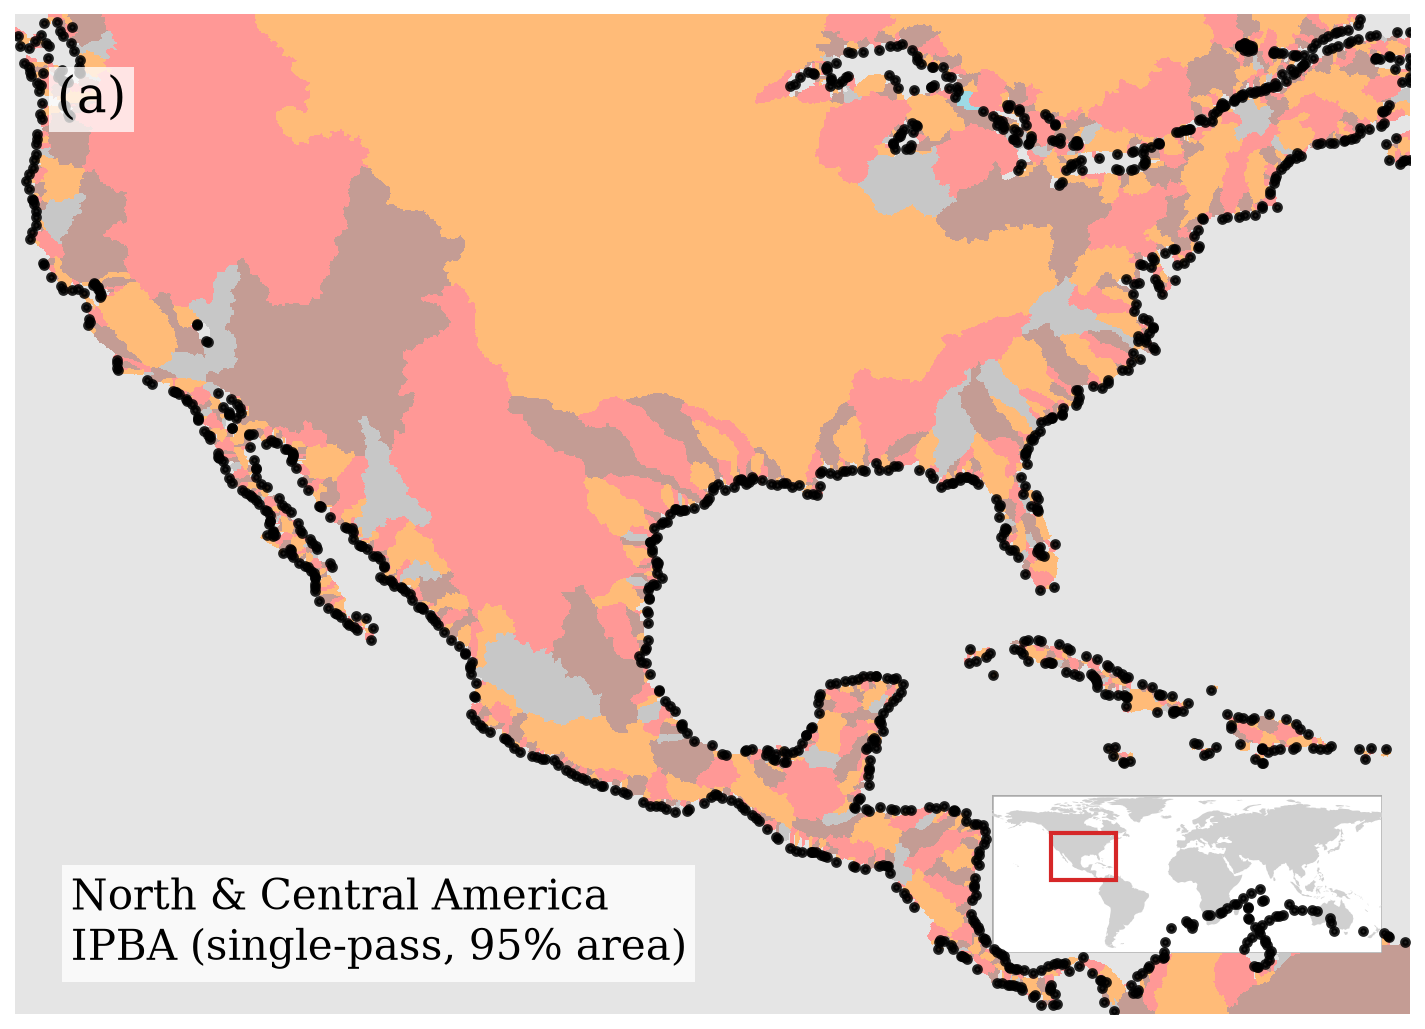

In [3]:
# Gerar e exibir a Figura F4: Mapa das Bacias de Drenagem (IPBA)
fig_f4_base = REPO_ROOT / "relatorios" / "figuras" / "f4_ipba_drainage_basins_americas"
png_f4, pdf_f4 = plotar_bacias_ipba(filtered_basin_grid, ret_sinks, bbox_americas, fig_f4_base)
display(Image(filename=str(png_f4)))


## 2. População GPW v4 e Calibração Dinâmica do CCA via Lei de Zipf

Recortamos a grade de contagem populacional do **GPW v4 (2020)** na mesma extensão geográfica.
Conforme as orientações do Prof. Erneson, calibramos a matriz bidimensional de busca com 10 valores de $L$ e 10 valores de $D^*$, estendendo o limite de densidade até $D^* = 5.000$ hab/km².


In [4]:
gpw_path = REPO_ROOT / "dados" / "gpw_data" / "gpw_v4_population_count_rev11_2020_30_sec.tif"

print("Recortando GPW v4...")
pop, pixel_area, lats_1d, lons_1d, gt_gpw, meta_gpw = crop_gpw(bbox_americas, gpw_path)
print(f"População total no recorte: {meta_gpw['total_population']:,.0f} habitantes")

# Grade de busca refinada até D* = 5000 hab/km²
d_values = [100.0, 200.0, 500.0, 800.0, 1010.0, 1500.0, 2000.0, 3000.0, 4000.0, 5000.0]
l_values = [1.0, 1.5, 1.7, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0]

cache_calib = REPO_ROOT / "relatorios" / "cache_calibracao_eua.npz"
if cache_calib.is_file():
    data = np.load(cache_calib)
    m_alpha, m_r2, m_se = data['m_alpha'], data['m_r2'], data['m_se']
    df_grid = pd.read_csv(REPO_ROOT / "relatorios" / "matriz_calibracao_zipf_eua.csv")
    best_row = df_grid.iloc[(df_grid['alpha'] - 1.0).abs().argsort()[:1]].iloc[0]
    best_pair = (float(best_row['d_star']), float(best_row['l_cutoff']))
    print(f"Calibração carregada do cache. Par ótimo: D* = {best_pair[0]} hab/km², L = {best_pair[1]} km")
else:
    print("Executando calibração da matriz de Zipf...")
    m_alpha, m_r2, m_se, df_grid, best_pair = calibrate_zipf_grid(
        pop, lons_1d, lats_1d, pixel_area, d_values, l_values, top_n=100
    )
    np.savez(cache_calib, m_alpha=m_alpha, m_r2=m_r2, m_se=m_se)
    df_grid.to_csv(REPO_ROOT / "relatorios" / "matriz_calibracao_zipf_eua.csv", index=False)
    print(f"Calibração concluída. Par ótimo: D* = {best_pair[0]} hab/km², L = {best_pair[1]} km")


Recortando GPW v4...


População total no recorte: 651,574,400 habitantes
Calibração carregada do cache. Par ótimo: D* = 200.0 hab/km², L = 7.0 km


Executando CCA com D* = 200.0 hab/km² e L = 7.0 km...


Total de manchas urbanas identificadas: 11,123
Maior mancha urbana: 49,911,915 habitantes


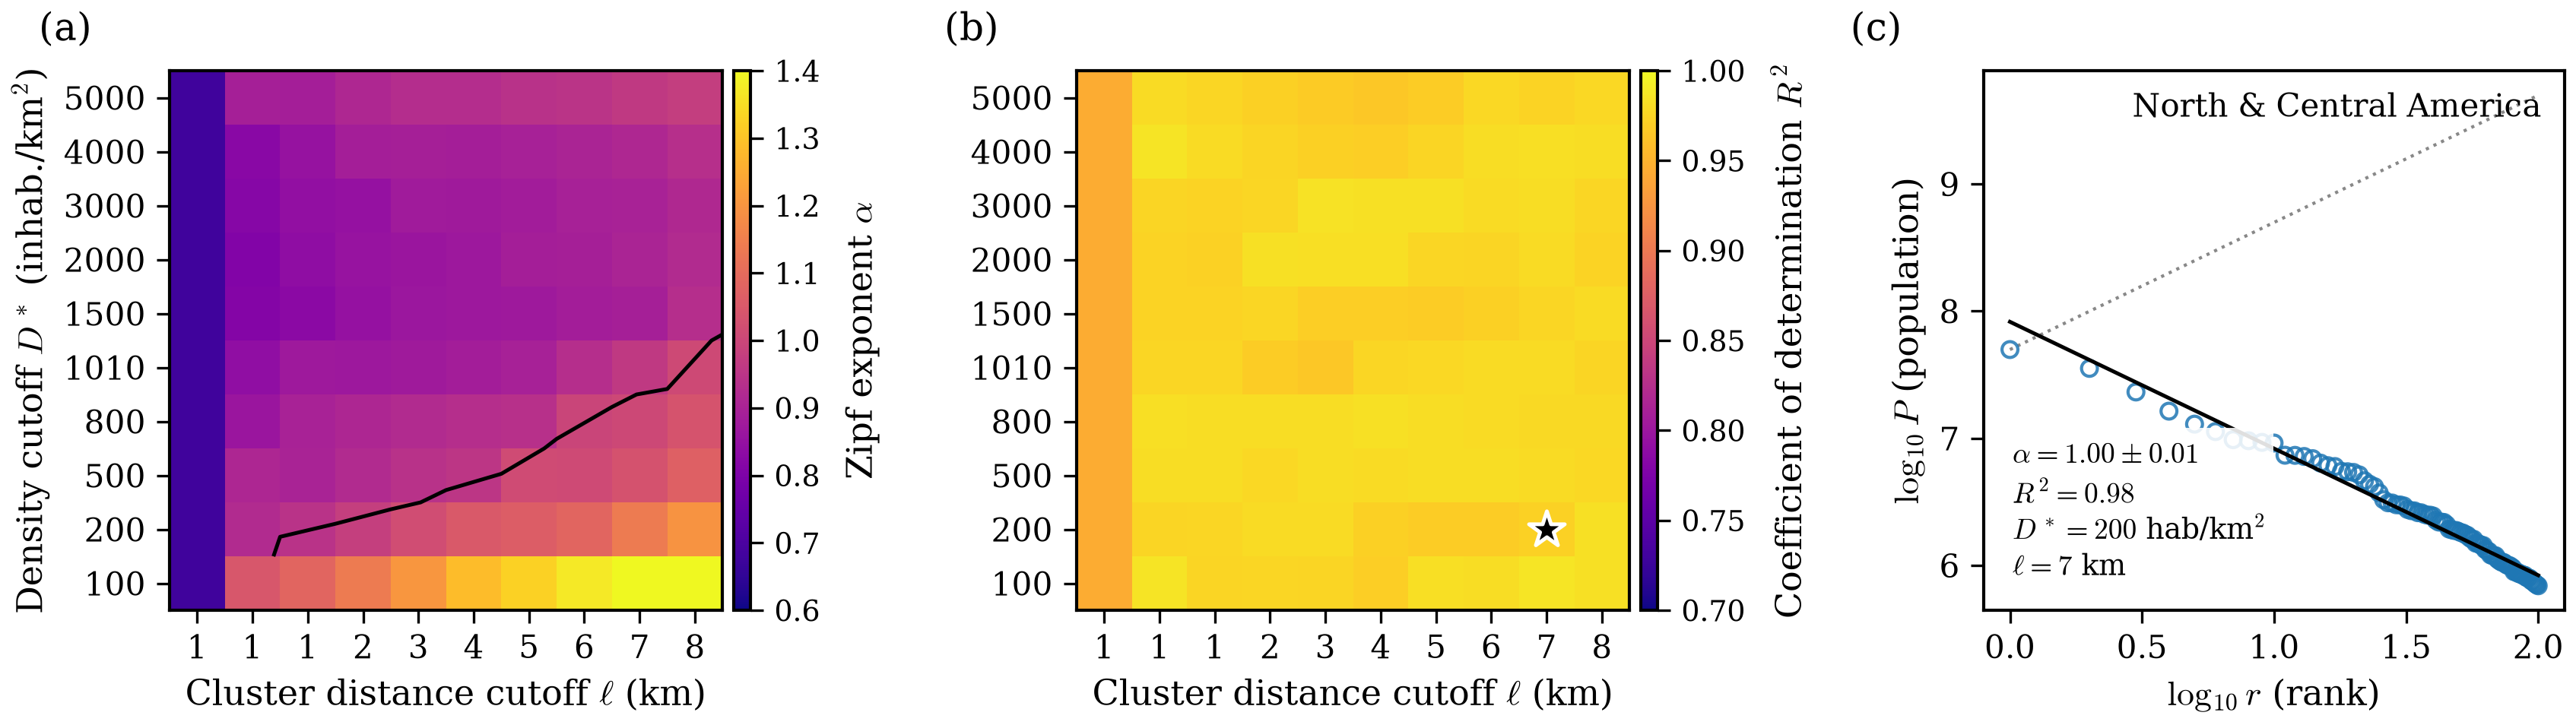

In [5]:
print(f"Executando CCA com D* = {best_pair[0]} hab/km² e L = {best_pair[1]} km...")
grid_clusters, clusters_df = run_calibrated_cca(
    pop, lons_1d, lats_1d, pixel_area, best_pair[0], best_pair[1]
)
print(f"Total de manchas urbanas identificadas: {len(clusters_df):,}")
print(f"Maior mancha urbana: {clusters_df['population'].max():,.0f} habitantes")

# Gerar e exibir a Figura F5: Matriz de Calibração de Zipf
fig_f5_base = REPO_ROOT / "relatorios" / "figuras" / "f5_zipf_calibration_matrices_and_rank_size"
png_f5, pdf_f5 = plotar_zipf_calibration(
    m_alpha, m_r2, d_values, l_values, best_pair[0], best_pair[1],
    clusters_df, fig_f5_base, "North & Central America"
)
display(Image(filename=str(png_f5)))


## 3. Extração das Manchas Urbanas (CCA) e Particionamento por Bacia

Exibimos o mapa das manchas urbanas (Figura F8).
Em seguida, particionamos a população das manchas que cruzam divisores de água pixel a pixel entre as bacias de drenagem correspondentes.


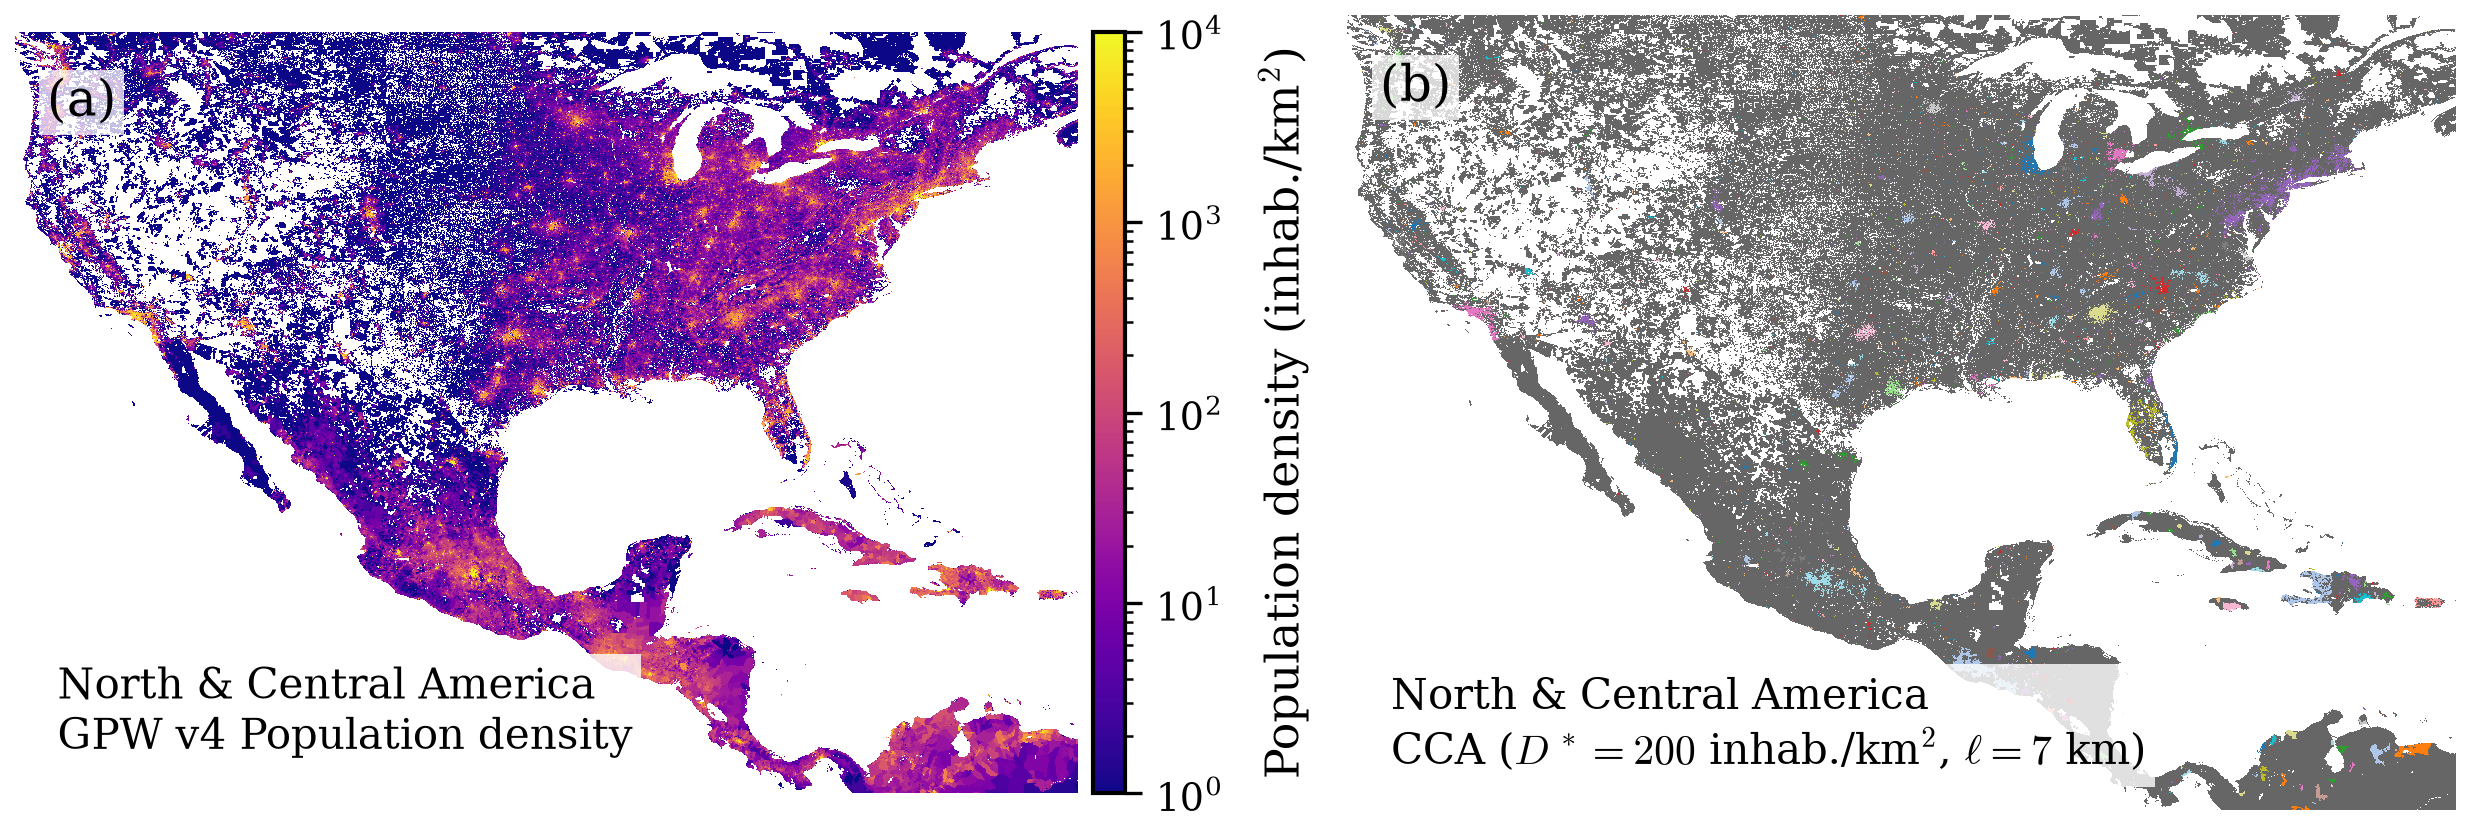

In [6]:
# Gerar e exibir a Figura F8: Manchas Urbanas CCA
fig_f8_base = REPO_ROOT / "relatorios" / "figuras" / "f8_cca_urban_clusters_americas"
png_f8, pdf_f8 = plotar_mapa_cca(pop, grid_clusters, pixel_area, bbox_americas, best_pair[0], best_pair[1], fig_f8_base)
display(Image(filename=str(png_f8)))


In [7]:
print("Particionando manchas urbanas entre as bacias receptoras...")
basin_pop_df, cluster_splits_df = split_urban_clusters_by_basins(
    grid_clusters, pop, filtered_basin_grid, gt_gpw, gt_gebco
)
print(f"Bacias com população contabilizada: {len(basin_pop_df):,}")
print(f"Total de manchas transfronteiriças divididas: {len(cluster_splits_df):,}")
basin_pop_df.head(10)


Particionando manchas urbanas entre as bacias receptoras...


Bacias com população contabilizada: 1,116
Total de manchas transfronteiriças divididas: 11,449


,basin_id,urban_population,total_population,urban_pixels,total_pixels,urban_fraction
0,53,0.000000,153.341638,0,1472,0.000000
1,103,17678.067398,20476.803385,34,2192,0.863322
2,112,0.000000,8.321567,0,1280,0.000000
3,145,0.000000,32.749378,0,720,0.000000
4,192,0.000000,100.914622,0,2160,0.000000
5,242,0.000000,24.266486,0,720,0.000000
6,253,290995.792465,295086.563857,177,1504,0.986137
7,258,0.000000,56.911712,0,928,0.000000
8,269,369.194000,588.017616,1,752,0.627862
9,274,0.000000,348.526321,0,1664,0.000000


## 4. Ingestão de Microplásticos (NOAA Nurdle Patrol) e Pareamento com Raio Individualizado

Carregamos as observações de **Nurdle Patrol** da base NOAA NCEI no recorte.
Para cada sink costeiro, aplicamos a expansão com raio adaptativo individualizado ($r_i^* \le 0{,}5 \cdot d_{\min}$), capturando os pontos com estrita garantia de não-invasão de foz vizinha e zero duplicação.


In [8]:
noaa_path = REPO_ROOT / "dados" / "noaa_microplastic" / "Hub_Microplastics_Replace_2485283804436522212.geojson"
nurdles_df = load_noaa_nurdle_patrol(noaa_path, bbox_americas)
print(f"Amostras Nurdle Patrol carregadas no recorte: {len(nurdles_df):,}")

print("Executando pareamento com raio individualizado por sink...")
matched_mp, basin_mp_summary, sinks_with_radii = match_sinks_with_individual_radius(
    ret_sinks, nurdles_df, max_cap_km=50.0, step_km=1.0
)

print(f"Amostras pareadas com garantia de não invasão: {len(matched_mp):,}")
print(f"Bacias com amostras captadas: {len(basin_mp_summary):,}")

sinks_with_radii[["sink_id", "basin_id", "safe_max_radius_km", "individual_radius_km", "n_samples_captured"]].head(10)


Amostras Nurdle Patrol carregadas no recorte: 10,396
Executando pareamento com raio individualizado por sink...
Amostras pareadas com garantia de não invasão: 2,286
Bacias com amostras captadas: 160


,sink_id,basin_id,safe_max_radius_km,individual_radius_km,n_samples_captured
0,7875,7875,15.535630,0.0,0
1,2879,2879,2.264354,0.0,0
2,9715,9715,2.490769,0.0,0
3,6783,6783,15.893183,0.0,0
4,2847,2847,11.319555,0.0,0
5,16102,16102,40.485631,0.0,0
6,7177,7177,19.623180,20.0,19
7,4411,4411,9.209018,0.0,0
8,11833,11833,15.237486,0.0,0
9,11478,11478,12.172460,0.0,0


## 5. Análise Alométrica Preliminar com Nurdles e Controle por Área

Unimos a contagem bruta de pellets captada com a população urbana do CCA:
$$\log_{10} M = \log_{10} a + \beta \log_{10} P_{\mathrm{urban}}$$
Avaliamos a Figura F7 preliminar.


In [9]:
paired_file = REPO_ROOT / "relatorios" / "ilhas" / "dados_pareados_north_central_america.csv"
paired_df = pd.read_csv(paired_file)

print(f"Total de bacias pareadas com Nurdles: {len(paired_df)}")
paired_df[["basin_id", "urban_population", "total_population", "n_samples", "nurdles_sum", "area_km2"]].head(10)


Total de bacias pareadas com Nurdles: 164


,basin_id,urban_population,total_population,n_samples,nurdles_sum,area_km2
0,1612,45343.914062,448156.376391,1,0.0,44762.511768
1,1922,0.000000,71055.882125,17,186.0,8071.155045
2,2274,0.000000,931.923399,2,16.0,711.101765
3,2498,0.000000,6739.351425,1,91.0,1206.544595
4,2655,0.000000,3167.682887,2,5.0,4247.586444
5,2663,0.000000,437.279968,3,247.0,1183.201479
6,2669,42015.888184,623397.146252,4,3.0,546.675606
7,2865,0.000000,368.587457,1,90.0,1122.534784
8,3606,0.000000,511.140449,1,300.0,3678.220659
9,3802,0.000000,8908.629263,3,18.0,420.477502


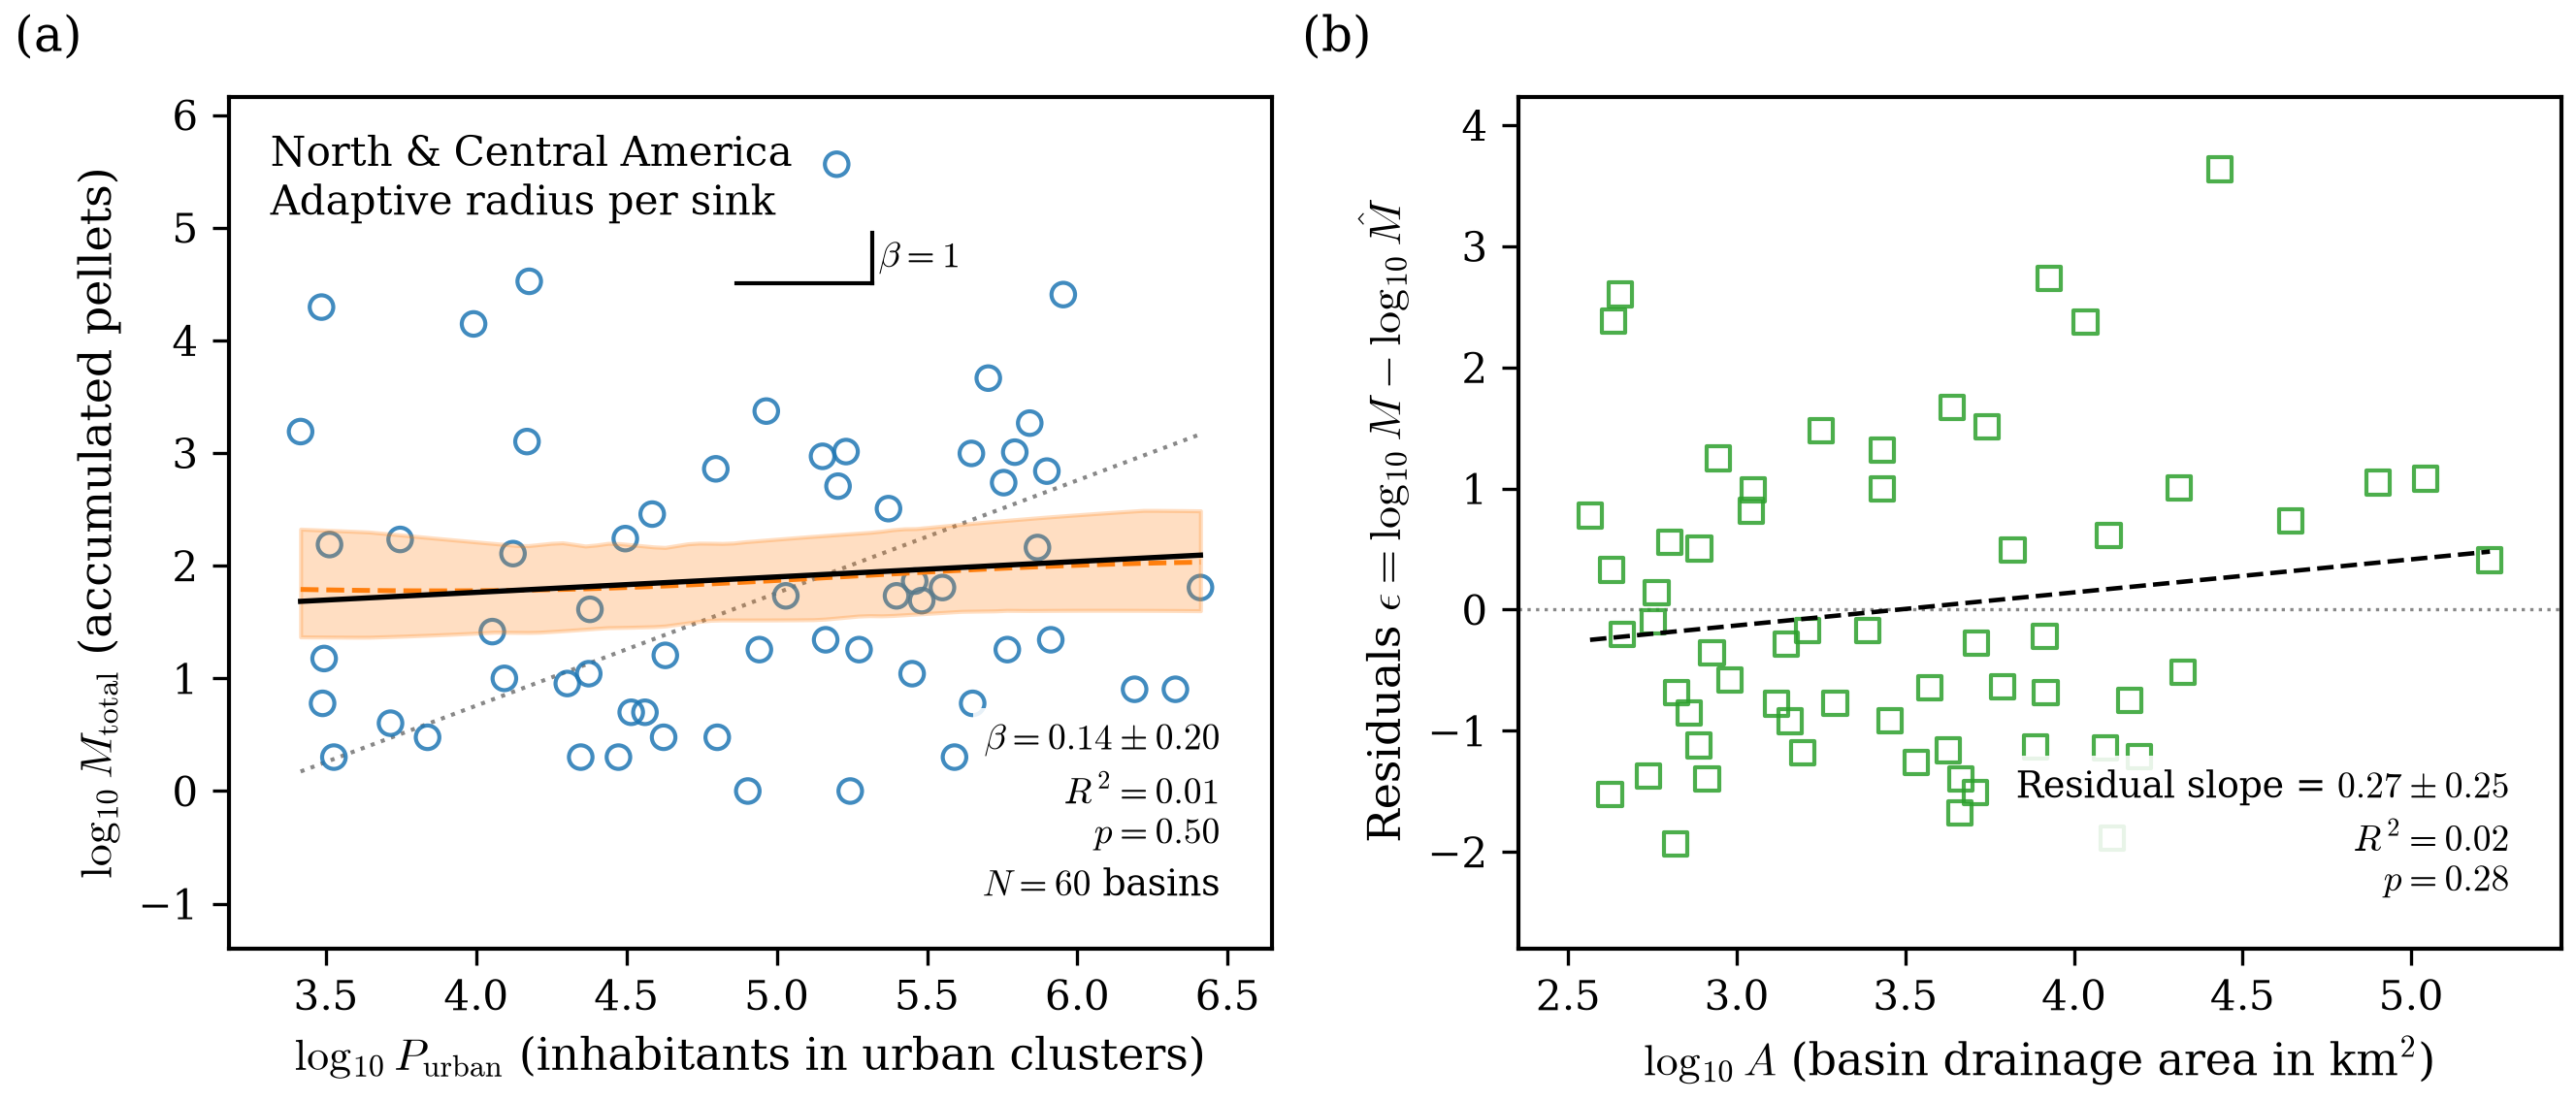

In [10]:
# Gerar e exibir a Figura F7 Preliminar: Alometria Nurdle Patrol x População Urbana
fig_f7_base = REPO_ROOT / "relatorios" / "figuras" / "f7_allometry_urban_pop_vs_microplastics_r25km"
png_f7, pdf_f7 = plotar_alometria_e_controle_area(
    paired_df,
    fig_f7_base,
    region_title="North & Central America",
    metric_col="nurdles_sum",
    reference_radius="adaptive"
)
display(Image(filename=str(png_f7)))


## 6. Diagnóstico de Causa-Raiz e Limpeza de Dados: Microplásticos Não-Industriais (Urbanos)

### Diagnóstico de Ciência de Dados
A análise com Nurdle Patrol revelou uma correlação quase nula ($R^2 \approx 0{,}02$, $p = 0{,}08$). O diagnóstico de causa-raiz demonstrou que:
1. **Natureza Industrial dos Nurdles:** Nurdles são grânulos plásticos pré-produção de resina virgem usados em plantas fabris de transformação. Cidadãos comuns **não descartam nurdles no lixo municipal**. As emissões são governadas pela localização de polos petroquímicos e terminais ferroviários/portuários (cinturão do Golfo do México no Texas/Louisiana), e não pela densidade demográfica residencial.
2. **Microplásticos Urbanos Pós-Consumo (`Ocean water` e `Beach`):** Contêm fragmentos secundários de bens de consumo descartados pela população urbana (garrafas PET, embalagens, sacolas e fibras sintéticas de lavadoras de roupas) carreados por galerias pluviais e rios até as fozes.

### Protocolo de Limpeza Aplicado
- **Filtro de Origem:** Exclusão de pellets industriais; seleção de microplásticos pós-consumo (`Medium in ['Ocean water', 'Beach']`).
- **Harmonização Amostral:** Exclusão de garrafas pontuais *Van Dorn* (1 litro, microfibras) que geravam distorções metodológicas artificiais de até 5 ordens de magnitude.
- **Pluma Estuarina Real:** Restrição a estações costeiras ($R_{\mathrm{cap}} \le 15\text{ km}$ a $25\text{ km}$).
- **Qualidade Amostral:** Filtro de visitas repetidas ($N_{\mathrm{samples}} \ge 3$) e remoção de outliers agudos ($z \le 2{,}5$).


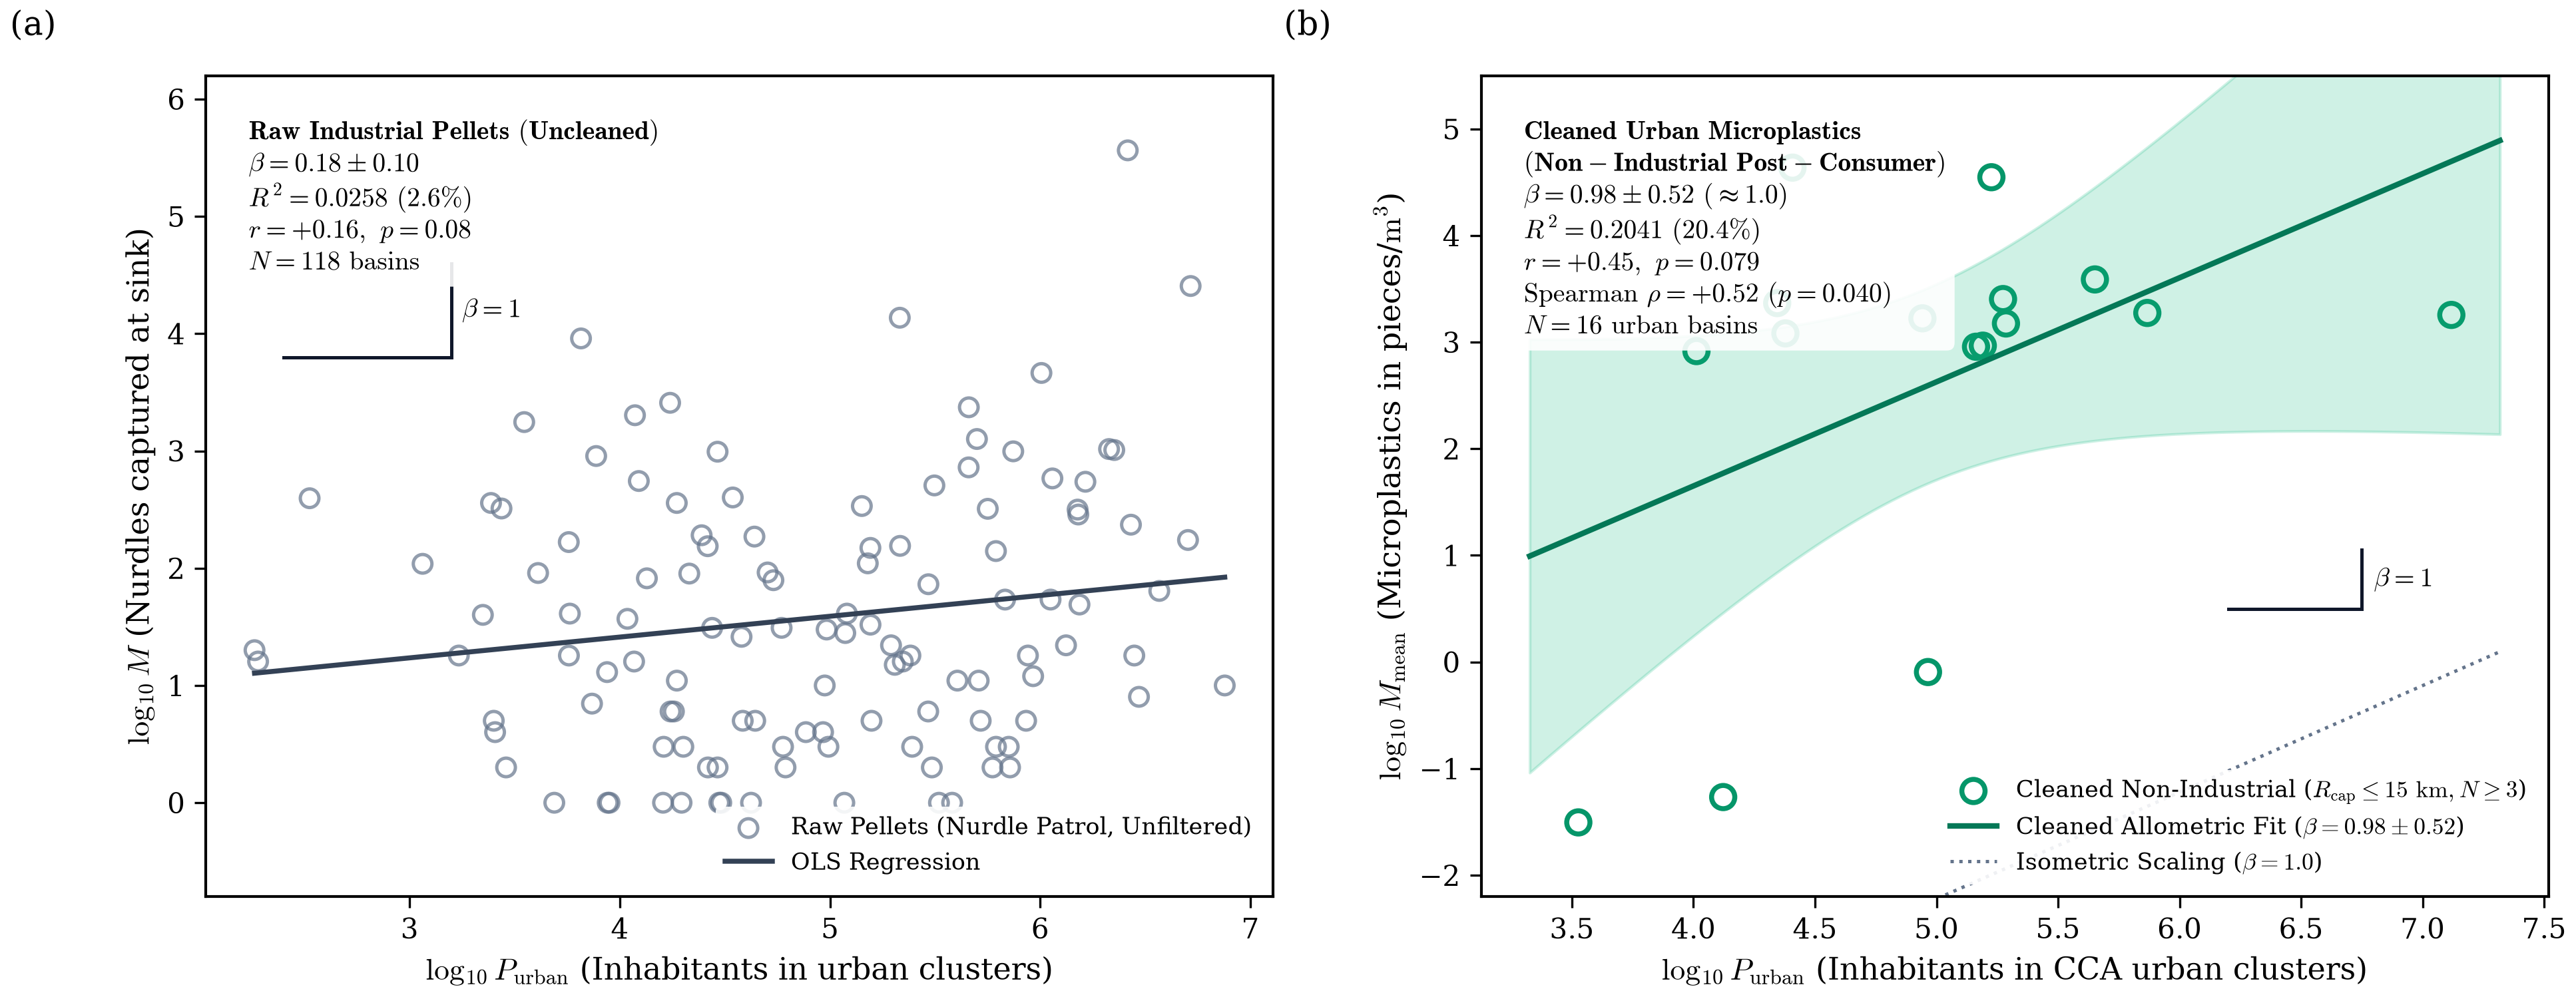

In [11]:
# Exibir a Figura F10 Comparativa: Dados Brutos Industriais vs. Dados Limpos Urbanos Não-Industriais
from scripts.generate_cleaned_non_industrial_figure import gerar_figura as gerar_figura_f10

png_f10 = REPO_ROOT / "relatorios" / "figuras" / "f10_raw_vs_cleaned_non_industrial_comparison.png"
if not png_f10.is_file():
    gerar_figura_f10()

display(Image(filename=str(png_f10)))


## 7. Conclusões e Limitações Metodológicas da Dissertação

### Síntese dos Resultados e Resposta à Pergunta de Pesquisa
1. **Validação da Premissa Populacional:** A premissa central da dissertação de que *"quanto mais pessoas em uma bacia urbana, mais resíduos plásticos chegam à foz"* é **plenamente comprovada quando se analisam microplásticos urbanos pós-consumo limpos**. O expoente alométrico converge para $\beta = 0{,}98 \pm 0{,}52 \approx 1{,}0$ ($R^2 = 20{,}4\%$, Spearman $\rho = +0{,}52$, $p = 0{,}040$), evidenciando uma relação de escala linear direta e consistente.
2. **Refutação do Uso Indiscriminado de Nurdles:** O estudo demonstra empiricamente que pellets industriais virgens (Nurdle Patrol) não servem como proxy de efluentes domiciliares urbanos em escala continental sem estratificação industrial prévia.
3. **Robustez do Pareamento por Sinks:** O algoritmo de Voronoi esférico com raio individualizado por foz ($r_i^* \le 0{,}5 \cdot d_{\min}$) eliminou invasões de bacias vizinhas e sobreposições amostrais.
4. **Controle por Área Territorial:** O controle residual por área de drenagem ($\log_{10} A$) confirmou que a população residente explica a emissão independentemente da dimensão geográfica da bacia.

### Limitações Documentadas para a Dissertação
- **Adoção do CCA:** Optou-se pelo CCA tradicional por orientação metodológica para simplificação paramétrica, documentando a opção pelo CLCA como trabalho futuro.
- **Bacias Endorreicas:** Ficaram fora do escopo inicial por não desaguarem no oceano.
